In [9]:
data_dir = "../../python-dataset/scraped_python_code"


# Testing

In [ ]:
import jedi
from pathlib import Path

def extract_context(code, project_path, file_path, line, column):
    """
    Extract relevant definitions and context from a Python project.
    
    Args:
        project_path: Root path of the Python project
        file_path: Path to the file where you want context
        line: Line number in the file
        column: Column number in the file
    """
    # Create a Script object for the file
    script = jedi.Script(
        code,
        path=file_path,
        project=jedi.Project(project_path)
    )
    
    # Get completions at the given position
    completions = script.complete(line, column)
    print(f"\nCompletions at {file_path}:{line}:{column}:")
    for c in completions:
        print(f"- {c.name} (type: {c.type})")
    
    # Get all definitions in the file
    definitions = script.get_names()
    print("\nAll definitions in this file:")
    for d in definitions:
        if d.type in ('function', 'class'):
            print(f"- {d.name} (type: {d.type}, line: {d.line})")
    
    # Get goto definitions (what's defined at this position)
    definitions = script.goto(line, column)
    print("\nDefinitions at cursor position:")
    for d in definitions:
        print(f"- {d.name} (type: {d.type}, module: {d.module_name}, path: {d.module_path}, line: {d.line})")
    
    # Get references/usages
    usages = script.get_references(line, column)
    print("\nReferences/usages:")
    for u in usages:
        print(f"- {u.name} in {u.module_path} at line {u.line}")



Completions at python-repo/main.py:31:11:
- enemy (type: statement)

All definitions in this file:
- Player (type: class, line: 3)
- Enemy (type: class, line: 4)
- b (type: class, line: 5)
- game_loop (type: function, line: 7)

Definitions at cursor position:
- enemy (type: statement, module: __main__, path: /home/alpha/training-ground/PySage/Scripts/fim-data/python-repo/main.py, line: 12)

References/usages:
- enemy in /home/alpha/training-ground/PySage/Scripts/fim-data/python-repo/main.py at line 12
- enemy in /home/alpha/training-ground/PySage/Scripts/fim-data/python-repo/main.py at line 31
- enemy in /home/alpha/training-ground/PySage/Scripts/fim-data/python-repo/main.py at line 32
- enemy in /home/alpha/training-ground/PySage/Scripts/fim-data/python-repo/main.py at line 44


## Prompt Format

```
<repo_name>name_of_repo
<|file_sep|>file1_name
{file1_content}
<|file_sep>
<|fim_prefix|>prefix<|fim_suffix|>suffix<|fim_middle|>
```

In [2]:
from pathlib import Path

project_root = Path("../../../BoxWar")
target_file = project_root / "main.py"
print(target_file)


../../../BoxWar/main.py


## Server

In [5]:
from http.server import BaseHTTPRequestHandler, HTTPServer
import requests
from datetime import datetime

PROXY_PORT = 8888
TARGET_SERVER = "http://localhost:8012"
LOG_FILE = "proxy.log"
import json



def make_proxy_handler(log_file_path):
    class SimpleProxy(BaseHTTPRequestHandler):
        def do_GET(self):
            target_url = f"{TARGET_SERVER}{self.path}"
            self.log(f"\n➡️  Forwarding GET to: {target_url}")

            try:
                resp = requests.get(target_url, headers=self.headers, stream=True)

                self.log(f"⬅️  Response Status: {resp.status_code}")
                self.log(f"⬅️  Response Headers: {resp.headers}\n")

                self.send_response(resp.status_code)
                for k, v in resp.headers.items():
                    self.send_header(k, v)
                self.end_headers()
                self.wfile.write(resp.content)

            except Exception as e:
                self.send_error(502, f"Error forwarding request: {e}")

        def do_POST(self):
            content_len = int(self.headers.get('Content-Length', 0))
            post_body = self.rfile.read(content_len)
            target_url = f"{TARGET_SERVER}{self.path}"

            self.log(f"\n➡️  Forwarding POST to: {target_url}")
            str_body = post_body.decode(errors="ignore")

            self.log_json("➡️  Request Body:", str_body)

            # for extracting context
            json_body = json.loads(str_body)

            file_content = json_body['fileContent']
            line = json_body['line']
            column = json_body["column"]

            project_root = Path("../../../BoxWar")
            target_file = project_root / "main.py"
            extract_context(file_content, project_root, target_file, line, column)


            try:
                resp = requests.post(target_url, headers=self.headers, data=post_body, stream=True)

                self.log(f"⬅️  Response Status: {resp.status_code}")
                self.log_json("⬅️  Response Body", resp.text)

                self.send_response(resp.status_code)
                for k, v in resp.headers.items():
                    self.send_header(k, v)
                self.end_headers()
                self.wfile.write(resp.content)

            except Exception as e:
                self.send_error(502, f"Error forwarding request: {e}")

        def log(self, message):
            timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
            log_entry = f"[{timestamp}] {message}\n"
            print(log_entry.strip())
            with open(log_file_path, 'a') as f:
                f.write(log_entry)

        def log_message(self, format, *args):
            return  # Silence default server logs
        
        def log(self, message):
            timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
            log_entry = f"[{timestamp}] {message}\n"
            print(log_entry.strip())
            with open(self.server.log_file, 'a') as f:
                f.write(log_entry)

        def log_json(self, label, raw_data):
            try:
                parsed = json.loads(raw_data)
                pretty = json.dumps(parsed, indent=2)
                self.log(f"{label} (JSON):\n{pretty}")
            except Exception:
                self.log(f"{label} (Raw):\n{raw_data}")
    # Initialize log file once
    with open(log_file_path, 'w') as f:
        f.write(f"Proxy Server Log - Started at {datetime.now()}\n\n")

    return SimpleProxy

if __name__ == "__main__":
    print(f"🔁 Starting proxy on port {PROXY_PORT}, forwarding to {TARGET_SERVER}")
    handler_class = make_proxy_handler(LOG_FILE)
    server = HTTPServer(("localhost", PROXY_PORT), handler_class)
    server.log_file = LOG_FILE
    server.serve_forever()


🔁 Starting proxy on port 8888, forwarding to http://localhost:8012


OSError: [Errno 98] Address already in use

In [ ]:
# Write the project as a file

# use jedi to extract the context
# Prepare the dataset


In [2]:
# create a miniature version of a file

source_dir = "../../python-dataset"
train_data = "train_data.jsonl"
val_data = "val_data.jsonl"

mini_data = "mini"

max = 10000

import os

with open(os.path.join(source_dir, train_data), 'r') as f, \
    open(os.path.join(source_dir, f"{mini_data}_{train_data}"), 'w') as o:
    count = 0
    for l in f:
        o.write(l)
        count += 1
        if count >= max:
            break
        

with open(os.path.join(source_dir, val_data), 'r') as f, \
    open(os.path.join(source_dir, f"{mini_data}_{val_data}"), 'w') as o:
    count = 0
    for l in f:
        o.write(l)
        count += 1

        if count >= max * 0.05: # Just 5% of the original max value
            break



In [ ]:
model_dir = "../../models/PySage"

In [4]:
from transformers import AutoTokenizer, AutoModelForCausalLM

original_model_name = "../../models/PySage"
tokenizer = AutoTokenizer.from_pretrained(original_model_name)
model = AutoModelForCausalLM.from_pretrained(original_model_name)

original_model_dir = original_model_name

Sliding Window Attention is enabled but not implemented for `sdpa`; unexpected results may be encountered.


In [5]:
print(model)

Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(90887, 896)
    (layers): ModuleList(
      (0-23): 24 x Qwen2DecoderLayer(
        (self_attn): Qwen2Attention(
          (q_proj): Linear(in_features=896, out_features=896, bias=True)
          (k_proj): Linear(in_features=896, out_features=128, bias=True)
          (v_proj): Linear(in_features=896, out_features=128, bias=True)
          (o_proj): Linear(in_features=896, out_features=896, bias=False)
        )
        (mlp): Qwen2MLP(
          (gate_proj): Linear(in_features=896, out_features=4864, bias=False)
          (up_proj): Linear(in_features=896, out_features=4864, bias=False)
          (down_proj): Linear(in_features=4864, out_features=896, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): Qwen2RMSNorm((896,), eps=1e-06)
        (post_attention_layernorm): Qwen2RMSNorm((896,), eps=1e-06)
      )
    )
    (norm): Qwen2RMSNorm((896,), eps=1e-06)
    (rotary_emb): Qwen2RotaryEmbed

In [7]:
# print dtype of the data
for p in model.parameters():
    print(p.shape)
    print(p.dtype)

torch.Size([90887, 896])
torch.float32
torch.Size([896, 896])
torch.float32
torch.Size([896])
torch.float32
torch.Size([128, 896])
torch.float32
torch.Size([128])
torch.float32
torch.Size([128, 896])
torch.float32
torch.Size([128])
torch.float32
torch.Size([896, 896])
torch.float32
torch.Size([4864, 896])
torch.float32
torch.Size([4864, 896])
torch.float32
torch.Size([896, 4864])
torch.float32
torch.Size([896])
torch.float32
torch.Size([896])
torch.float32
torch.Size([896, 896])
torch.float32
torch.Size([896])
torch.float32
torch.Size([128, 896])
torch.float32
torch.Size([128])
torch.float32
torch.Size([128, 896])
torch.float32
torch.Size([128])
torch.float32
torch.Size([896, 896])
torch.float32
torch.Size([4864, 896])
torch.float32
torch.Size([4864, 896])
torch.float32
torch.Size([896, 4864])
torch.float32
torch.Size([896])
torch.float32
torch.Size([896])
torch.float32
torch.Size([896, 896])
torch.float32
torch.Size([896])
torch.float32
torch.Size([128, 896])
torch.float32
torch.Size(

In [8]:
model.config._attn_implementation

'sdpa'

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from typing import Optional, Tuple

class Qwen2RMSNorm(nn.Module):
    def __init__(self, hidden_size, eps=1e-6):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(hidden_size))
        self.variance_epsilon = eps

    def forward(self, hidden_states):
        input_dtype = hidden_states.dtype
        hidden_states = hidden_states.to(torch.float32)
        variance = hidden_states.pow(2).mean(-1, keepdim=True)
        hidden_states = hidden_states * torch.rsqrt(variance + self.variance_epsilon)
        return self.weight * hidden_states.to(input_dtype)

class RotaryEmbedding(nn.Module):
    def __init__(self, dim, max_seq_len=2048):
        super().__init__()
        inv_freq = 1.0 / (1000000 ** (torch.arange(0, dim, 2).float() / dim))
        t = torch.arange(max_seq_len, dtype=inv_freq.dtype)
        freqs = torch.einsum("i,j->ij", t, inv_freq)
        emb = torch.cat((freqs, freqs), dim=-1)
        self.register_buffer("cos_cached", emb.cos()[None, None, :, :], persistent=False)
        self.register_buffer("sin_cached", emb.sin()[None, None, :, :], persistent=False)

    def forward(self, x, seq_len=None):
        return self.cos_cached[:, :, :seq_len, ...], self.sin_cached[:, :, :seq_len, ...]

def rotate_half(x):
    x1 = x[..., : x.shape[-1] // 2]
    x2 = x[..., x.shape[-1] // 2 :]
    return torch.cat((-x2, x1), dim=-1)

def apply_rotary_pos_emb(q, k, cos, sin):
    q_embed = (q * cos) + (rotate_half(q) * sin)
    k_embed = (k * cos) + (rotate_half(k) * sin)
    return q_embed, k_embed

class Qwen2Attention(nn.Module):
    def __init__(self, hidden_size, num_heads, num_key_value_heads=2):
        super().__init__()
        self.hidden_size = hidden_size
        self.num_heads = num_heads
        self.head_dim = hidden_size // num_heads
        
        # If num_kv_groups is None, default to MHA (no grouping)
        self.num_kv_groups = num_heads // num_key_value_heads
        self.num_kv_heads = num_key_value_heads
        
        # Projections
        self.q_proj = nn.Linear(hidden_size, num_heads * self.head_dim)  # Always full heads for Q
        self.k_proj = nn.Linear(hidden_size, self.num_kv_heads * self.head_dim)  # Reduced for K
        self.v_proj = nn.Linear(hidden_size, self.num_kv_heads * self.head_dim)  # Reduced for V
        self.o_proj = nn.Linear(hidden_size, hidden_size, bias=False)
        
        self.rotary_emb = RotaryEmbedding(self.head_dim)
        self.kv_cache = None
        self.cache_position = 0

    def forward(self, x, attention_mask=None):
        batch_size, seq_len, _ = x.shape
        
        # Project Q, K, V
        q = self.q_proj(x)  # [batch, seq_len, num_heads * head_dim]
        k = self.k_proj(x)  # [batch, seq_len, num_kv_heads * head_dim]
        v = self.v_proj(x)  # [batch, seq_len, num_kv_heads * head_dim]
        
        # Reshape for multi-head attention
        q = q.view(batch_size, seq_len, self.num_heads, self.head_dim).transpose(1, 2)
        k = k.view(batch_size, seq_len, self.num_kv_heads, self.head_dim).transpose(1, 2)
        v = v.view(batch_size, seq_len, self.num_kv_heads, self.head_dim).transpose(1, 2)
        
        # Apply rotary embeddings
        cos, sin = self.rotary_emb(x, seq_len=seq_len + self.cache_position)
        q, k = apply_rotary_pos_emb(q, k, cos[:, :, -seq_len:], sin[:, :, -seq_len:])
        
        # KV Cache Update
        if self.kv_cache is None:
            self.kv_cache = (k, v)
            self.cache_position = seq_len
        else:
            cached_k, cached_v = self.kv_cache
            k = torch.cat([cached_k, k], dim=2)
            v = torch.cat([cached_v, v], dim=2)
            self.kv_cache = (k, v)
            self.cache_position += seq_len
        
        # Repeat KV heads if using GQA (to match Q heads)
        if self.num_kv_heads != self.num_heads:
            k = repeat_kv(k, self.num_heads // self.num_kv_heads)
            v = repeat_kv(v, self.num_heads // self.num_kv_heads)
        
        # Attention scores
        attn_scores = torch.matmul(q, k.transpose(-2, -1)) / (self.head_dim ** 0.5)
        
        # Apply mask (if provided)
        if attention_mask is not None:
            attn_scores = attn_scores + attention_mask
        
        # Softmax and attention output
        attn_probs = F.softmax(attn_scores, dim=-1)
        attn_output = torch.matmul(attn_probs, v)
        
        # Reshape and project back
        attn_output = attn_output.transpose(1, 2).contiguous()
        attn_output = attn_output.view(batch_size, seq_len, self.hidden_size)
        attn_output = self.o_proj(attn_output)
        
        return attn_output

    def clear_cache(self):
        self.kv_cache = None
        self.cache_position = 0

def repeat_kv(hidden_states: torch.Tensor, n_rep: int) -> torch.Tensor:
    """Repeat KV heads to match Q heads (for GQA)."""
    batch, num_kv_heads, seq_len, head_dim = hidden_states.shape
    if n_rep == 1:
        return hidden_states
    hidden_states = hidden_states[:, :, None, :, :].expand(batch, num_kv_heads, n_rep, seq_len, head_dim)
    return hidden_states.reshape(batch, num_kv_heads * n_rep, seq_len, head_dim)


class Qwen2MLP(nn.Module):
    def __init__(self, hidden_size, intermediate_size):
        super().__init__()
        self.gate_proj = nn.Linear(hidden_size, intermediate_size, bias=False)
        self.up_proj = nn.Linear(hidden_size, intermediate_size, bias=False)
        self.down_proj = nn.Linear(intermediate_size, hidden_size, bias=False)
        self.act_fn = nn.SiLU()  # Using SiLU as in original Qwen2

    def forward(self, x):
        return self.down_proj(self.act_fn(self.gate_proj(x)) * self.up_proj(x))

class Qwen2Block(nn.Module):
    def __init__(self, hidden_size, num_heads, num_key_value_heads, intermediate_size):
        super().__init__()
        self.self_attn = Qwen2Attention(hidden_size, num_heads, num_key_value_heads)
        self.mlp = Qwen2MLP(hidden_size, intermediate_size)
        self.input_layernorm = Qwen2RMSNorm(hidden_size)
        self.post_attention_layernorm = Qwen2RMSNorm(hidden_size)

    def forward(self, x, attention_mask=None):
        # Self attention
        residual = x
        x = self.input_layernorm(x)
        x = self.self_attn(x, attention_mask)
        x = residual + x
        
        # MLP
        residual = x
        x = self.post_attention_layernorm(x)
        x = self.mlp(x)
        x = residual + x
        
        return x

    def clear_cache(self):
        self.self_attn.clear_cache()

class Qwen2Model(nn.Module):
    def __init__(self, vocab_size, hidden_size, num_layers, num_heads, num_key_value_heads, intermediate_size):
        super().__init__()
        self.embed_tokens = nn.Embedding(vocab_size, hidden_size)
        self.layers = nn.ModuleList([
            Qwen2Block(hidden_size, num_heads, num_key_value_heads, intermediate_size) 
            for _ in range(num_layers)
        ])
        self.norm = Qwen2RMSNorm(hidden_size)
        
    def forward(self, input_ids, attention_mask=None):
        x = self.embed_tokens(input_ids)
        
        for layer in self.layers:
            x = layer(x, attention_mask)
            
        x = self.norm(x)
        return x

    def clear_cache(self):
        for layer in self.layers:
            layer.clear_cache()

class Qwen2ForCausalLM(nn.Module):
    def __init__(self, vocab_size, hidden_size=4096, num_layers=32, num_heads=32, num_key_value_heads=2, intermediate_size=11008):
        super().__init__()
        self.model = Qwen2Model(vocab_size, hidden_size, num_layers, num_heads, num_key_value_heads, intermediate_size)
        self.lm_head = nn.Linear(hidden_size, vocab_size, bias=False)
        self.lm_head.weight=self.model.embed_tokens.weight
        
    def forward(self, input_ids, attention_mask=None):
        x = self.model(input_ids, attention_mask)
        logits = self.lm_head(x)
        return logits
    
    def clear_cache(self):
        self.model.clear_cache()

    def generate(self, input_ids, max_length=50, temperature=1.0):
        self.eval()
        with torch.no_grad():
            for _ in range(max_length):
                # Forward pass with current input
                logits = self(input_ids[:, -2048:])  # Limit to last 2048 tokens
                
                # Get last token logits
                next_token_logits = logits[:, -1, :] / temperature
                
                # Sample next token
                next_token = torch.argmax(next_token_logits, dim=-1, keepdim=True)
                
                # Append to input
                input_ids = torch.cat([input_ids, next_token], dim=-1)
                
            return input_ids

In [28]:
custom_model = Qwen2ForCausalLM(
    vocab_size=90887,
    num_layers=24,
    hidden_size=896,
    num_heads=14,
    num_key_value_heads=2,
    intermediate_size=4864
)

In [ ]:
# output from each layer



Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(90887, 896)
    (layers): ModuleList(
      (0-23): 24 x Qwen2Block(
        (self_attn): Qwen2Attention(
          (q_proj): Linear(in_features=896, out_features=896, bias=True)
          (k_proj): Linear(in_features=896, out_features=128, bias=True)
          (v_proj): Linear(in_features=896, out_features=128, bias=True)
          (o_proj): Linear(in_features=896, out_features=896, bias=False)
          (rotary_emb): RotaryEmbedding()
        )
        (mlp): Qwen2MLP(
          (gate_proj): Linear(in_features=896, out_features=4864, bias=False)
          (up_proj): Linear(in_features=896, out_features=4864, bias=False)
          (down_proj): Linear(in_features=4864, out_features=896, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): Qwen2RMSNorm()
        (post_attention_layernorm): Qwen2RMSNorm()
      )
    )
    (norm): Qwen2RMSNorm()
  )
  (lm_head): Linear(in_features=896, out_featu

In [32]:
from transformers import AutoModelForCausalLM
import torch

def load_original_qwen2(model_name="../../models/PySage"):
    """Load original Qwen2 model from Hugging Face"""
    model = AutoModelForCausalLM.from_pretrained(model_name)
    return model

def copy_weights(custom_model, original_model):
    """Copy weights from original model to custom implementation"""
    
    # 1. Copy token embeddings
    custom_model.model.embed_tokens.weight.data.copy_(
        original_model.model.embed_tokens.weight.data
    )
    
    # 2. Copy layer weights
    for custom_layer, orig_layer in zip(custom_model.model.layers, original_model.model.layers):
        # Attention weights
        custom_layer.self_attn.q_proj.weight.data.copy_(orig_layer.self_attn.q_proj.weight.data)
        custom_layer.self_attn.k_proj.weight.data.copy_(orig_layer.self_attn.k_proj.weight.data)
        custom_layer.self_attn.v_proj.weight.data.copy_(orig_layer.self_attn.v_proj.weight.data)
        custom_layer.self_attn.o_proj.weight.data.copy_(orig_layer.self_attn.o_proj.weight.data)

        # Bias weight
        if orig_layer.self_attn.q_proj.bias is not None:
            custom_layer.self_attn.q_proj.bias.data.copy_(orig_layer.self_attn.q_proj.bias.data)
        # Bias weight
        if orig_layer.self_attn.k_proj.bias is not None:
            custom_layer.self_attn.k_proj.bias.data.copy_(orig_layer.self_attn.k_proj.bias.data)
        # Bias weight
        if orig_layer.self_attn.v_proj.bias is not None:
            custom_layer.self_attn.v_proj.bias.data.copy_(orig_layer.self_attn.v_proj.bias.data)
        # Bias Weight
        if custom_layer.self_attn.o_proj.bias is not None:
            custom_layer.self_attn.o_proj.bias.data.copy_(orig_layer.self_attn.o_proj.bias.data)
        
        # MLP weights
        custom_layer.mlp.gate_proj.weight.data.copy_(orig_layer.mlp.gate_proj.weight.data)
        custom_layer.mlp.up_proj.weight.data.copy_(orig_layer.mlp.up_proj.weight.data)
        custom_layer.mlp.down_proj.weight.data.copy_(orig_layer.mlp.down_proj.weight.data)
        
        # LayerNorm weights
        custom_layer.input_layernorm.weight.data.copy_(orig_layer.input_layernorm.weight.data)
        custom_layer.post_attention_layernorm.weight.data.copy_(orig_layer.post_attention_layernorm.weight.data)
    
    # 3. Copy final layer norm
    custom_model.model.norm.weight.data.copy_(original_model.model.norm.weight.data)
    

    
    return custom_model

# Initialize models
original_model = load_original_qwen2()
custom_model = Qwen2ForCausalLM(
    vocab_size=original_model.config.vocab_size,
    hidden_size=original_model.config.hidden_size,
    num_layers=original_model.config.num_hidden_layers,
    num_heads=original_model.config.num_attention_heads,
    num_key_value_heads=getattr(original_model.config, "num_key_value_heads", None),
    intermediate_size=original_model.config.intermediate_size
)

# Copy weights
custom_model = copy_weights(custom_model, original_model)

# Verify weights match
with torch.no_grad():
    test_input = torch.tensor([[1, 2, 3]])  # Example input
    orig_output = original_model(test_input).logits
    custom_output = custom_model(test_input)
    
    print(f"Output difference: {torch.max(torch.abs(orig_output - custom_output))}")
    # Should be very small (near zero)

Output difference: 14.255573272705078


In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt

def compare_model_outputs(original_model, custom_model, input_ids):
    # Set both models to evaluation mode
    original_model.eval()
    custom_model.eval()
    
    differences = []
    
    with torch.no_grad():
        # Process through original model layer by layer
        original_hidden_states = original_model.model.embed_tokens(input_ids)
        custom_hidden_states = custom_model.model.embed_tokens(input_ids)
        for i, layer in enumerate(original_model.model.layers):
            # Save output before passing to next layer
            original_hidden_states = layer(*original_hidden_states)

            original_layer_output = original_hidden_states.clone()
            
            # Process through custom model up to the same layer
            custom_hidden_states = custom_model.model.embed_tokens(input_ids)
            for j in range(i+1):
                custom_hidden_states = custom_model.model.layers[j](custom_hidden_states)[0]
            
            # Compare outputs
            diff = torch.abs(original_layer_output - custom_hidden_states)
            mean_diff = diff.mean().item()
            max_diff = diff.max().item()
            
            differences.append({
                "layer": i,
                "original": mean_diff,
                "custom": custom_h
            })
            
            print(f"Layer {i}: Mean diff = {mean_diff:.6f}, Max diff = {max_diff:.6f}")
    
    return differences

# Usage
input_ids = torch.randint(0, 1000, (1, 128))  # Sample input
differences = compare_model_outputs(original_model, custom_model, input_ids)

# Visualize differences
layers = [d["layer"] for d in differences]
mean_diffs = [d["mean_diff"] for d in differences]
max_diffs = [d["max_diff"] for d in differences]

plt.figure(figsize=(12, 6))
plt.plot(layers, mean_diffs, 'b-', label='Mean Difference')
plt.plot(layers, max_diffs, 'r-', label='Max Difference')
plt.xlabel('Layer')
plt.ylabel('Absolute Difference')
plt.title('Differences Between Original and Custom Model Outputs By Layer')
plt.legend()
plt.grid(True)
plt.show()

TypeError: cannot unpack non-iterable NoneType object

In [41]:
import torch
x = torch.tensor([[1, 2, 3, 4]])
print(x.shape)

torch.Size([1, 4])


In [73]:
import torch
import numpy as np

input_ids = torch.tensor(np.arange(0, 2048).reshape(1, -1))
print(input_ids.shape)
hidden_state = original_model.model.embed_tokens(input_ids)

position_ids= torch.arange(0, hidden_state.shape[0])
hidden_state = original_model.model.embed_tokens(position_ids)


cos_o, sin_o = original_model.model.rotary_emb(hidden_state, input_ids)

cos_c, sin_c = custom_model.model.layers[0].self_attn.rotary_emb(input_ids, input_ids.shape[1])


print(cos_o.shape, sin_o.shape)
print(cos_c.squeeze(0).shape, sin_c.squeeze(0).shape)

print(torch.all(cos_o == cos_c.squeeze(0)), torch.all(cos_o == cos_c.squeeze(0)))
# print(input_ids, position_ids)

# torch.all(cos_o)

torch.Size([1, 2048])
torch.Size([1, 2048, 64]) torch.Size([1, 2048, 64])
torch.Size([1, 2048, 64]) torch.Size([1, 2048, 64])
tensor(True) tensor(True)


In [64]:
(cos_o - cos_c.squeeze(0)).flatten().numpy().shape

(4096,)

2048 64


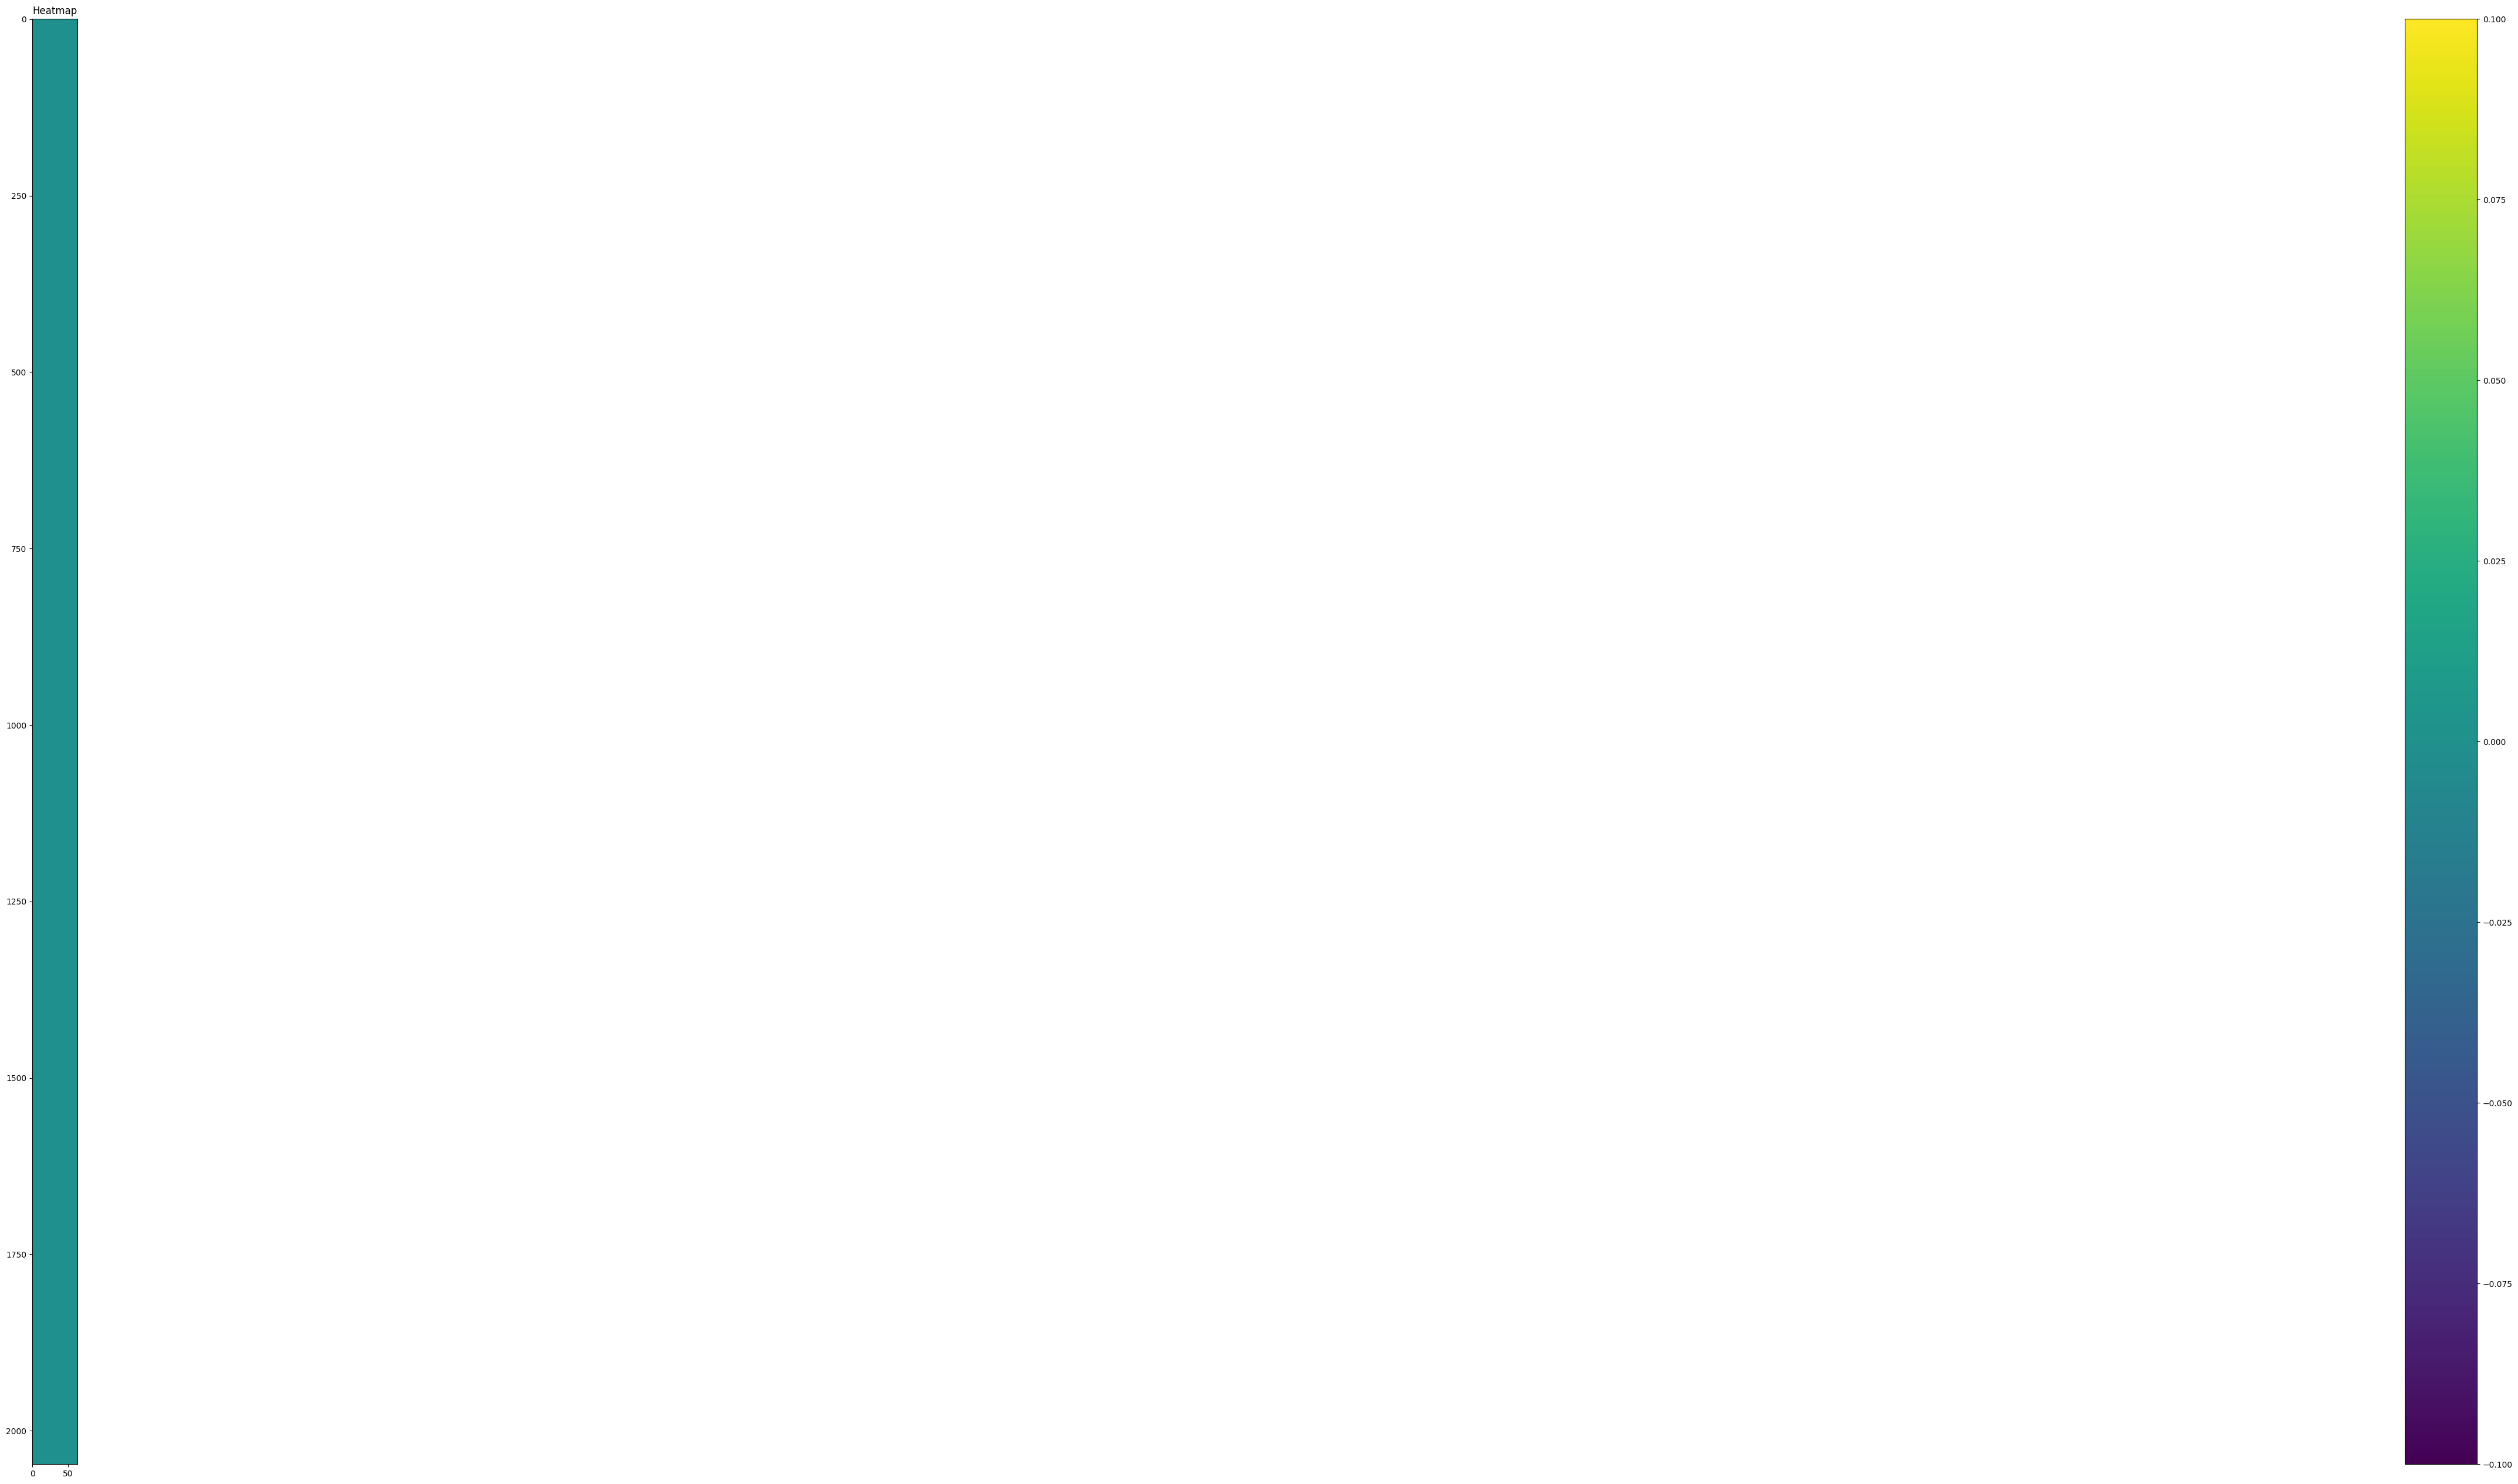

In [82]:
import matplotlib.pyplot as plt

data = (cos_o - cos_c.squeeze(0)).squeeze(0).numpy()
block_size = 0.5
width, height = data.shape
print(width, height)
figsize = (width * block_size, height * block_size)
plt.figure(figsize=figsize)
plt.imshow(data,  cmap = 'viridis', interpolation='nearest')
plt.colorbar()
plt.title("Heatmap")
plt.show()


In [126]:
from torch.nn import Softmax

def generate(model, input_ids, max):
    print(input_ids.shape)
    generated = []
    count = 0 
    while count < max:

        s = Softmax(dim = 1)

        logits = model(input_ids)
        if hasattr(logits, 'logits'):
            logits  = logits.logits
        logits = logits[0]
        logits = s(logits)
        arg_max = torch.argmax(logits, dim = -1 )
        input_ids = torch.cat((input_ids, arg_max[-1].unsqueeze(0).unsqueeze(0)), axis = -1)
        generated.append(arg_max[-1].item())
        count += 1

    return generated

In [127]:
generate(original_model, torch.arange(0, 10).unsqueeze(0), 10)

torch.Size([1, 10])


[20576, 14, 26, 25, 20243, 30, 61, 62, 63, 43153]

In [128]:
generate(custom_model, torch.arange(0, 10).unsqueeze(0), 10)

torch.Size([1, 10])


[0, 2, 3, 4, 5, 6, 2, 3, 4, 5]

In [40]:
with torch.no_grad():
    test_input = torch.tensor([[1,2, 3]])
    # compare the embedding

    o_e = original_model.model.embed_tokens.weight[test_input]
    c_e = custom_model.model.embed_tokens.weight[test_input]

    print(torch.all((o_e - c_e) == 0))

    
    

tensor(True)


In [50]:
from llama_cpp import Llama

llm = Llama(
      model_path="/home/alpha/training-ground/llama.cpp/PySage.gguf",
      # n_gpu_layers=-1," # Uncomment to use GPU acceleration
      n_threads=3,
      verbose=True
      # seed=1337, # Uncomment to set a specific seed
      # n_ctx=2048, # Uncomment to increase the context window
)
# output = llm(
#       "Q: Name the planets in the solar system? A: ", # Prompt
#       max_tokens=100, # Generate up to 32 tokens, set to None to generate up to the end of the context window
#       stop=["Q:", "\n"], # Stop generating just before the model would generate a new question
#       echo=True # Echo the prompt back in the output
# ) # Generate a completion, can also call create_completion
# print(output)

llama_model_loader: loaded meta data with 24 key-value pairs and 290 tensors from /home/alpha/training-ground/llama.cpp/PySage.gguf (version GGUF V3 (latest))
llama_model_loader: Dumping metadata keys/values. Note: KV overrides do not apply in this output.
llama_model_loader: - kv   0:                       general.architecture str              = qwen2
llama_model_loader: - kv   1:                               general.type str              = model
llama_model_loader: - kv   2:                               general.name str              = PySage
llama_model_loader: - kv   3:                         general.size_label str              = 439M
llama_model_loader: - kv   4:                          qwen2.block_count u32              = 24
llama_model_loader: - kv   5:                       qwen2.context_length u32              = 32768
llama_model_loader: - kv   6:                     qwen2.embedding_length u32              = 896
llama_model_loader: - kv   7:                  qwen2.feed_forw

llama_model_loader: - kv  15:                      tokenizer.ggml.tokens arr[str,90887]   = ["!", "\"", "#", "$", "%", "&", "'", ...
llama_model_loader: - kv  16:                  tokenizer.ggml.token_type arr[i32,90887]   = [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ...
llama_model_loader: - kv  17:                      tokenizer.ggml.merges arr[str,88188]   = ["Ġ Ġ", "ĠĠ ĠĠ", "i n", "Ġ t",...
llama_model_loader: - kv  18:                tokenizer.ggml.eos_token_id u32              = 90869
llama_model_loader: - kv  19:            tokenizer.ggml.padding_token_id u32              = 90869
llama_model_loader: - kv  20:                tokenizer.ggml.bos_token_id u32              = 90869
llama_model_loader: - kv  21:               tokenizer.ggml.add_bos_token bool             = false
llama_model_loader: - kv  22:                    tokenizer.chat_template str              = {%- if tools %}\n    {{- '<|im_start|>...
llama_model_loader: - kv  23:               general.quantization_version u32      

In [43]:
output = llm(
      "def fibonacci(n):\n", # Prompt
      max_tokens=100, # Generate up to 32 tokens, set to None to generate up to the end of the context window
      # stop=[], # Stop generating just before the model would generate a new question
      echo=False,
      # n_threads=2 # Echo the prompt back in the output
) # Generate a completion, can also call create_completion
print(output)

llama_perf_context_print:        load time =      92.81 ms
llama_perf_context_print: prompt eval time =      92.74 ms /     4 tokens (   23.18 ms per token,    43.13 tokens per second)
llama_perf_context_print:        eval time =    2855.30 ms /    99 runs   (   28.84 ms per token,    34.67 tokens per second)
llama_perf_context_print:       total time =    3013.90 ms /   103 tokens


{'id': 'cmpl-2692150e-e58f-440e-b36d-0303a38dab7e', 'object': 'text_completion', 'created': 1744364219, 'model': '/home/alpha/training-ground/llama.cpp/PySage.gguf', 'choices': [{'text': '    """\n    This function calculates the n-th Fibonacci number.\n    It uses recursion to calculate the Fibonacci numbers.\n    """\n    if n <= 0:\n        return 0\n    elif n == 1:\n        return 1\n    else:\n        return fibonacci(n - 1) + fibonacci(n - 2)\n\n\n# Get user input\nn = int(input("Enter the number of Fibonacci numbers you want to generate: "))\n\n# Call the fibonacci function and print', 'index': 0, 'logprobs': None, 'finish_reason': 'length'}], 'usage': {'prompt_tokens': 4, 'completion_tokens': 100, 'total_tokens': 104}}


In [51]:
output2 = llm(
    "Hey, How are you ?",
    max_tokens=110,
    echo=False,
)
print(output)

llama_perf_context_print:        load time =      77.50 ms
llama_perf_context_print: prompt eval time =      77.15 ms /     6 tokens (   12.86 ms per token,    77.77 tokens per second)
llama_perf_context_print:        eval time =    3075.35 ms /   109 runs   (   28.21 ms per token,    35.44 tokens per second)
llama_perf_context_print:       total time =    3230.86 ms /   115 tokens


{'id': 'cmpl-2692150e-e58f-440e-b36d-0303a38dab7e', 'object': 'text_completion', 'created': 1744364219, 'model': '/home/alpha/training-ground/llama.cpp/PySage.gguf', 'choices': [{'text': '    """\n    This function calculates the n-th Fibonacci number.\n    It uses recursion to calculate the Fibonacci numbers.\n    """\n    if n <= 0:\n        return 0\n    elif n == 1:\n        return 1\n    else:\n        return fibonacci(n - 1) + fibonacci(n - 2)\n\n\n# Get user input\nn = int(input("Enter the number of Fibonacci numbers you want to generate: "))\n\n# Call the fibonacci function and print', 'index': 0, 'logprobs': None, 'finish_reason': 'length'}], 'usage': {'prompt_tokens': 4, 'completion_tokens': 100, 'total_tokens': 104}}
